<a href="https://colab.research.google.com/github/Suchitra2017/Plant-Disease-ViT/blob/main/Plant_Disease_ViT_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets transformers evaluate accelerate

In [ ]:
# Download the original PlantVillage dataset
!git clone -q https://github.com/spMohanty/PlantVillage-Dataset.git

print("PlantVillage dataset downloaded successfully!")

PlantVillage dataset downloaded successfully!


In [ ]:
import os

DATASET_PATH = "/content/PlantVillage-Dataset/raw/color"

classes = sorted(os.listdir(DATASET_PATH))

print("Dataset path:", DATASET_PATH)
print("Number of classes:", len(classes))

print("\nFirst 10 classes:")
for cls in classes[:10]:
    print(cls)

Dataset path: /content/PlantVillage-Dataset/raw/color
Number of classes: 38

First 10 classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight


In [ ]:
import pandas as pd

# Count the number of images in each class
class_counts = {}

for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[class_name] = len(image_files)

# Convert results to a DataFrame
class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

# Sort from largest to smallest
class_distribution = class_distribution.sort_values(
    by="Number of Images",
    ascending=False
).reset_index(drop=True)

# Display summary
print("Total number of images:", class_distribution["Number of Images"].sum())
print("Number of classes:", len(class_distribution))

print("\nLargest class:")
print(class_distribution.iloc[0])

print("\nSmallest class:")
print(class_distribution.iloc[-1])

print("\nClass Distribution:")
display(class_distribution)

Total number of images: 54305
Number of classes: 38

Largest class:
Class               Orange___Haunglongbing_(Citrus_greening)
Number of Images                                        5507
Name: 0, dtype: object

Smallest class:
Class               Potato___healthy
Number of Images                 152
Name: 37, dtype: object

Class Distribution:


,Class,Number of Images
0,Orange___Haunglongbing_(Citrus_greening),5507
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
2,Soybean___healthy,5090
3,Peach___Bacterial_spot,2297
4,Tomato___Bacterial_spot,2127
5,Tomato___Late_blight,1909
6,Squash___Powdery_mildew,1835
7,Tomato___Septoria_leaf_spot,1771
8,Tomato___Spider_mites Two-spotted_spider_mite,1676
9,Apple___healthy,1645


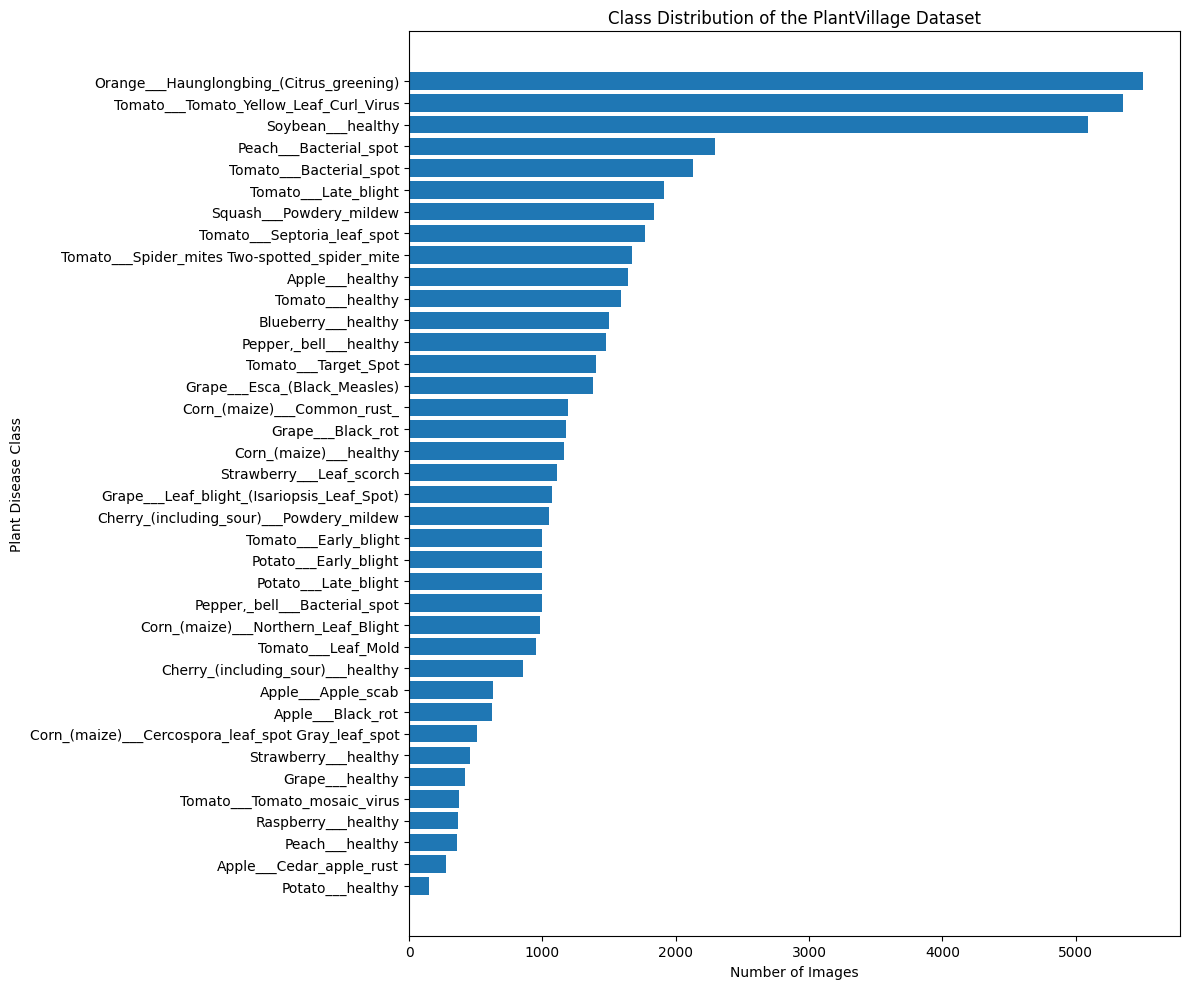

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.barh(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("Class Distribution of the PlantVillage Dataset")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

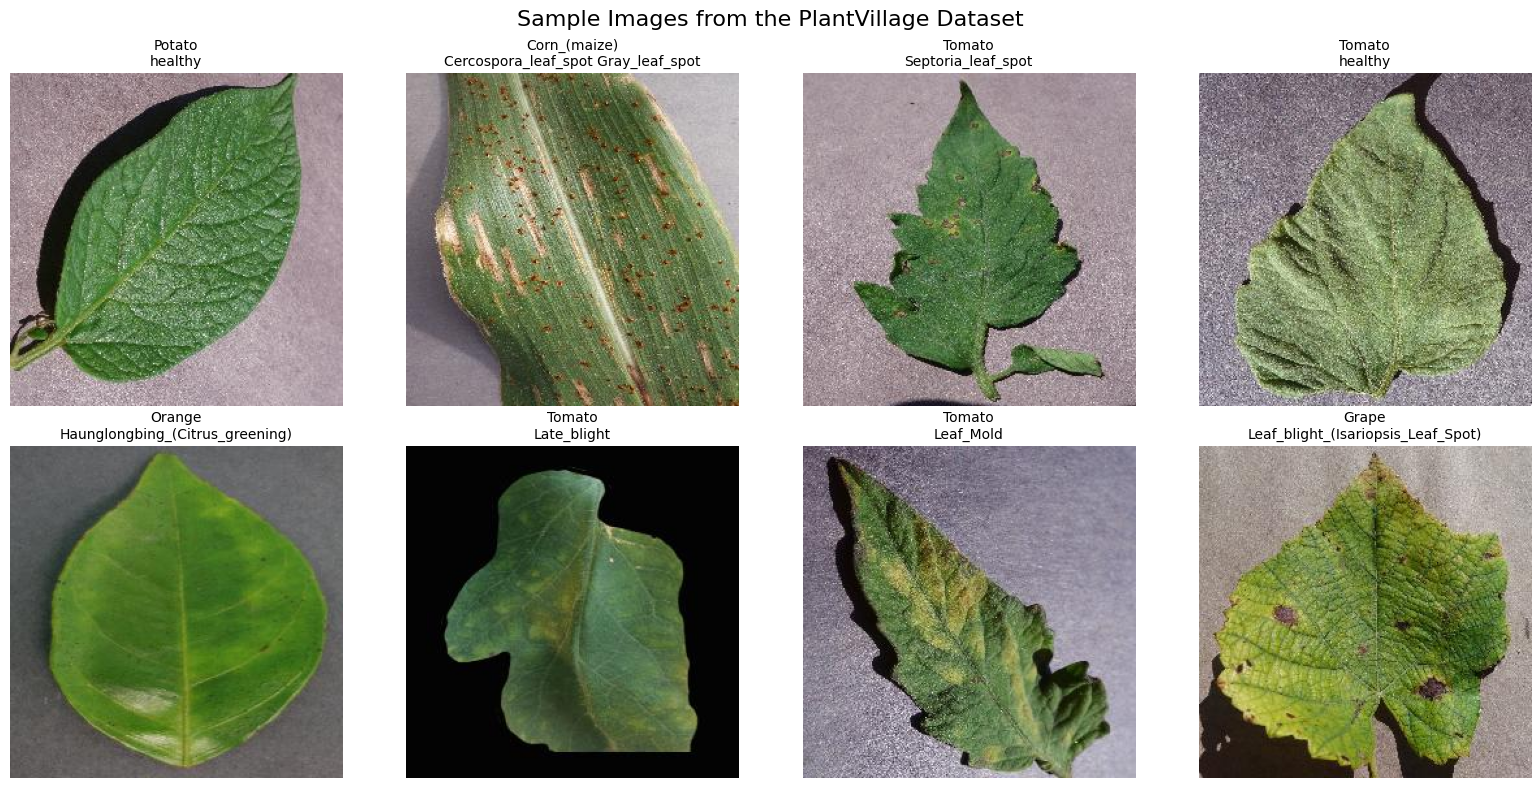

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Select 8 different classes randomly
sample_classes = random.sample(classes, 8)

plt.figure(figsize=(16, 8))

for i, class_name in enumerate(sample_classes):
    class_path = os.path.join(DATASET_PATH, class_name)

    # Get image files
    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Select one image randomly
    image_file = random.choice(image_files)
    image_path = os.path.join(class_path, image_file)

    # Load image
    image = Image.open(image_path)

    # Display
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)

    # Make class name easier to read
    display_name = class_name.replace("___", "\n")
    plt.title(display_name, fontsize=10)
    plt.axis("off")

plt.suptitle(
    "Sample Images from the PlantVillage Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import os

print("Files/folders in PlantVillage repository:\n")

for item in sorted(os.listdir("/content/PlantVillage-Dataset")):
    print(item)

Files/folders in PlantVillage repository:

.git
.gitignore
CITATION.cff
README.md
README_HF.md
data_distribution_for_SVM
generate_data_for_SVM.py
generate_lmdb.sh
generate_mapstring.py
generated_for_paper
leaf-map.json
leaf_grouping
logs
plant_village.py
raw
scripts
utils


In [ ]:
import os

LEAF_GROUPING_PATH = "/content/PlantVillage-Dataset/leaf_grouping"

print("Contents of leaf_grouping:\n")

if os.path.isdir(LEAF_GROUPING_PATH):
    for item in sorted(os.listdir(LEAF_GROUPING_PATH))[:30]:
        print(item)
else:
    print("leaf_grouping is a file, not a folder.")

    with open(LEAF_GROUPING_PATH, "r") as f:
        for i in range(20):
            line = f.readline()
            if not line:
                break
            print(line.strip())

Contents of leaf_grouping:

Google Leaf Counts.zip
aggregate_map.py
create_map.py
filtered_leafmaps
leaf-map.json
leaf_maps


In [ ]:
import json
import os

LEAF_MAP_PATH = "/content/PlantVillage-Dataset/leaf_grouping/leaf-map.json"

with open(LEAF_MAP_PATH, "r") as f:
    leaf_map = json.load(f)

print("Data type:", type(leaf_map))
print("Number of entries:", len(leaf_map))

print("\nFirst 5 entries:")

if isinstance(leaf_map, dict):
    for i, (key, value) in enumerate(leaf_map.items()):
        print("\nKEY:", key)
        print("VALUE:", value)

        if i == 4:
            break
else:
    for item in leaf_map[:5]:
        print(item)

Data type: <class 'dict'>
Number of entries: 40328

First 5 entries:

KEY: rutg._hl 3733
VALUE: ['Peach___healthy:::54.0']

KEY: com.g_fl 8310
VALUE: ['Tomato___Target_Spot:::243.0']

KEY: rs_early.b 7557
VALUE: ['Potato___Early_blight:::115.0']

KEY: rs_early.b 7554
VALUE: ['Potato___Early_blight:::115.0']

KEY: uf.citrus_hlb_lab 1658
VALUE: ['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [ ]:
# Inspect actual image filenames from a few classes

for class_name in classes[:3]:
    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("\nCLASS:", class_name)
    print("Number of images:", len(image_files))
    print("First 5 filenames:")

    for filename in image_files[:5]:
        print("  ", filename)


CLASS: Apple___Apple_scab
Number of images: 630
First 5 filenames:
   4b4b59d5-3c6d-4ce5-b349-616fecb850ff___FREC_Scab 3447.JPG
   7ed79254-3e04-4e08-9c80-088cd9d7d8c9___FREC_Scab 3310.JPG
   1f97d75c-db85-4344-8687-82ca56454d17___FREC_Scab 3408.JPG
   da09f1db-51a0-4142-855a-7783a3f92114___FREC_Scab 2978.JPG
   daf6db9e-a600-449c-8b66-482ab50ea431___FREC_Scab 3237.JPG

CLASS: Apple___Black_rot
Number of images: 621
First 5 filenames:
   4c42eeae-508c-4ccd-b2d8-b720808bc28c___JR_FrgE.S 3020.JPG
   1d59f109-9793-403b-88d7-73bc3b17d601___JR_FrgE.S 8592.JPG
   a2e4f04e-63f9-4c66-aa1b-bf0f0b6937dc___JR_FrgE.S 8756.JPG
   b2d126c0-49f9-4013-a6bf-2c08ffe87f94___JR_FrgE.S 2865.JPG
   05421496-3901-424d-b44a-1be1f2734cf1___JR_FrgE.S 3005.JPG

CLASS: Apple___Cedar_apple_rust
Number of images: 275
First 5 filenames:
   d5d4f65c-aeca-4965-82d4-05d179dfa92e___FREC_C.Rust 4382.JPG
   f2c49716-d630-4dfa-8104-e98b8a9d7497___FREC_C.Rust 9897.JPG
   6a858b72-4061-4fa1-a83d-04d83f83ad77___FREC_C.Rust 4

In [ ]:
MAPPING_SCRIPT = "/content/PlantVillage-Dataset/leaf_grouping/create_map.py"

with open(MAPPING_SCRIPT, "r") as f:
    mapping_code = f.read()

print(mapping_code)

#!/usr/bin/env python


# -*- coding: utf-8 -*-
import xlrd
import csv
from os import sys
import glob

def csv_from_excel(excel_file, target_prefix):
    workbook = xlrd.open_workbook(excel_file)
    all_worksheets = workbook.sheet_names()
    for worksheet_name in all_worksheets:
        worksheet = workbook.sheet_by_name(worksheet_name)
        your_csv_file = open(target_prefix+"_"+''.join([worksheet_name,'.csv']), 'wb')
        wr = csv.writer(your_csv_file, quoting=csv.QUOTE_ALL)

        for rownum in xrange(worksheet.nrows):
            wr.writerow([unicode(entry).encode("utf-8") for entry in worksheet.row_values(rownum)])
        your_csv_file.close()


for _file in glob.glob("leaf_maps/*"):
	print _file
	
	csv_from_excel(_file, _file.replace(" Leaf Counts.xlsx",""))



In [ ]:
import os
import pandas as pd

records = []

for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(class_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, filename)

            records.append({
                "image_path": image_path,
                "label": class_name
            })

# Create DataFrame
df = pd.DataFrame(records)

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

print("\nFirst 5 records:")
display(df.head())

Total images: 54305
Total classes: 38

First 5 records:


,image_path,label
0,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab
1,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab
2,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab
3,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab
4,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab


In [ ]:
from sklearn.model_selection import train_test_split

# Step 1: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Step 2: Split remaining 30% equally
# 15% validation and 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display results
print("Total dataset:", len(df))
print()
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print()
print("Training percentage:",
      round(len(train_df) / len(df) * 100, 2), "%")

print("Validation percentage:",
      round(len(val_df) / len(df) * 100, 2), "%")

print("Test percentage:",
      round(len(test_df) / len(df) * 100, 2), "%")

Total dataset: 54305

Training images: 38013
Validation images: 8146
Test images: 8146

Training percentage: 70.0 %
Validation percentage: 15.0 %
Test percentage: 15.0 %


In [ ]:
print("Classes in Validation set:", val_df["label"].nunique())
print("Classes in Test set:", test_df["label"].nunique())

# Check for any missing classes
all_classes = set(df["label"].unique())

missing_train = all_classes - set(train_df["label"].unique())
missing_val = all_classes - set(val_df["label"].unique())
missing_test = all_classes - set(test_df["label"].unique())

print("\nMissing classes in Training:", missing_train)
print("Missing classes in Validation:", missing_val)
print("Missing classes in Test:", missing_test)

Classes in Validation set: 38
Classes in Test set: 38

Missing classes in Training: set()
Missing classes in Validation: set()
Missing classes in Test: set()


In [ ]:
# Create mappings between class names and numeric labels

label_names = sorted(df["label"].unique())

label2id = {
    label: idx
    for idx, label in enumerate(label_names)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

# Add numeric labels to each dataset
train_df["label_id"] = train_df["label"].map(label2id)
val_df["label_id"] = val_df["label"].map(label2id)
test_df["label_id"] = test_df["label"].map(label2id)

print("Number of labels:", len(label2id))

print("\nFirst 10 label mappings:")
for label in label_names[:10]:
    print(f"{label2id[label]:2d} -> {label}")

print("\nTraining dataset:")
display(train_df.head())

Number of labels: 38

First 10 label mappings:
 0 -> Apple___Apple_scab
 1 -> Apple___Black_rot
 2 -> Apple___Cedar_apple_rust
 3 -> Apple___healthy
 4 -> Blueberry___healthy
 5 -> Cherry_(including_sour)___Powdery_mildew
 6 -> Cherry_(including_sour)___healthy
 7 -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8 -> Corn_(maize)___Common_rust_
 9 -> Corn_(maize)___Northern_Leaf_Blight

Training dataset:


,image_path,label,label_id
0,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Cedar_apple_rust,2
1,/content/PlantVillage-Dataset/raw/color/Raspbe...,Raspberry___healthy,23
2,/content/PlantVillage-Dataset/raw/color/Tomato...,Tomato___Late_blight,30
3,/content/PlantVillage-Dataset/raw/color/Potato...,Potato___Early_blight,20
4,/content/PlantVillage-Dataset/raw/color/Corn_(...,Corn_(maize)___healthy,10


In [ ]:
README_PATH = "/content/PlantVillage-Dataset/README_HF.md"

with open(README_PATH, "r") as f:
    readme_text = f.read()

# Print the sections mentioning leaf IDs or splitting
for line in readme_text.splitlines():
    if any(word in line.lower() for word in
           ["leaf_id", "split", "train", "test"]):
        print(line)

  - name: leaf_id
  splits:
  - name: train
  - name: test
The dataset comes with pre-defined **80/20 train/test splits** that preserve the leaf grouping logic (ensuring images of the same leaf do not appear in both sets).
# This automatically downloads the train and test splits.
#     train: Dataset({ features: [...], num_rows: 43596 }),
#     test: Dataset({ features: [...], num_rows: 10709 })
## Advanced: Custom Splitting
**Note:** The dataset **already includes** a standard train/test split (as shown in Quick Start), which is recommended for benchmarking. The instructions below are only for **advanced users** who require custom cross-validation folds.
If you require a different split ratio or cross-validation scheme, you **must** strictly respect the `leaf_id` to prevent data leakage. Multiple images often capture the same physical leaf; separating them across train/test sets will bias your evaluation.
Here is a complete example of how to reshuffle and split the dataset 80/20:
# 1.

In [ ]:
import os

# Look for the official split files in the repository
split_files = []

for root, dirs, files in os.walk("/content/PlantVillage-Dataset"):
    for file in files:
        if file in ["color_train.txt", "color_test.txt"]:
            split_files.append(os.path.join(root, file))

print("Official color split files found:")
for file in split_files:
    print(file)

Official color split files found:


In [ ]:
import json
import os

# Load leaf grouping metadata
LEAF_MAP_PATH = "/content/PlantVillage-Dataset/leaf_grouping/leaf-map.json"

with open(LEAF_MAP_PATH, "r") as f:
    leaf_map = json.load(f)

# Examine one actual RGB image
sample_class = "Apple___Apple_scab"
sample_folder = os.path.join(DATASET_PATH, sample_class)

sample_file = os.listdir(sample_folder)[0]

print("Actual RGB filename:")
print(sample_file)

print("\nOriginal filename portion:")
original_name = sample_file.split("___", 1)[1]
print(original_name)

print("\nTotal leaf-map entries:")
print(len(leaf_map))

# Search metadata keys related to the original filename
search_text = os.path.splitext(original_name)[0]

matches = [
    (key, value)
    for key, value in leaf_map.items()
    if key.lower() in search_text.lower()
    or search_text.lower() in key.lower()
]

print("\nMatching leaf-map entries:")
for match in matches[:10]:
    print(match)

print("\nNumber of matches:", len(matches))

Actual RGB filename:
4b4b59d5-3c6d-4ce5-b349-616fecb850ff___FREC_Scab 3447.JPG

Original filename portion:
FREC_Scab 3447.JPG

Total leaf-map entries:
40328

Matching leaf-map entries:
('frec_scab 3447', ['Apple___Apple_scab:::97.0'])

Number of matches: 1


In [ ]:
import os
import json
from collections import defaultdict

# Load leaf-map metadata
LEAF_MAP_PATH = "/content/PlantVillage-Dataset/leaf_grouping/leaf-map.json"

with open(LEAF_MAP_PATH, "r") as f:
    leaf_map = json.load(f)

# Make leaf-map keys lowercase for matching
leaf_map_lower = {
    key.lower(): value
    for key, value in leaf_map.items()
}

mapped_records = []
unmapped_records = []
ambiguous_records = []

# Process every RGB image
for _, row in df.iterrows():

    image_path = row["image_path"]
    class_name = row["label"]

    filename = os.path.basename(image_path)

    # Remove UUID prefix
    if "___" in filename:
        original_filename = filename.split("___", 1)[1]
    else:
        original_filename = filename

    # Remove extension
    original_key = os.path.splitext(original_filename)[0].lower()

    # Exact lookup
    if original_key in leaf_map_lower:

        mapping_values = leaf_map_lower[original_key]

        if len(mapping_values) == 1:

            mapping = mapping_values[0]

            # Example:
            # Apple___Apple_scab:::97.0
            mapped_class, leaf_id = mapping.rsplit(":::", 1)

            mapped_records.append({
                "image_path": image_path,
                "label": class_name,
                "label_id": label2id[class_name],
                "leaf_id": f"{mapped_class}::{leaf_id}"
            })

        else:
            ambiguous_records.append({
                "image_path": image_path,
                "matches": mapping_values
            })

    else:
        unmapped_records.append({
            "image_path": image_path,
            "original_key": original_key
        })

# Convert mapped images to DataFrame
leaf_df = pd.DataFrame(mapped_records)

print("===== LEAF MAPPING SUMMARY =====")
print("Total RGB images:", len(df))
print("Successfully mapped:", len(mapped_records))
print("Unmapped:", len(unmapped_records))
print("Ambiguous:", len(ambiguous_records))

if len(leaf_df) > 0:
    print("Unique leaf groups:", leaf_df["leaf_id"].nunique())

    print("\nFirst 5 mapped records:")
    display(leaf_df.head())

===== LEAF MAPPING SUMMARY =====
Total RGB images: 54305
Successfully mapped: 36741
Unmapped: 13194
Ambiguous: 4370
Unique leaf groups: 7078

First 5 mapped records:


,image_path,label,label_id,leaf_id
0,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab,0,Apple___Apple_scab::97.0
1,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab,0,Apple___Apple_scab::75.0
2,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab,0,Apple___Apple_scab::90.0
3,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab,0,Apple___Apple_scab::15.0
4,/content/PlantVillage-Dataset/raw/color/Apple_...,Apple___Apple_scab,0,Apple___Apple_scab::62.0


In [ ]:
from transformers import AutoImageProcessor

MODEL_NAME = "google/vit-base-patch16-224-in21k"

image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

print("ViT Image Processor loaded successfully!")

print("\nImage size:")
print(image_processor.size)

print("\nNormalization mean:")
print(image_processor.image_mean)

print("\nNormalization standard deviation:")
print(image_processor.image_std)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

ViT Image Processor loaded successfully!

Image size:
SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)

Normalization mean:
(0.5, 0.5, 0.5)

Normalization standard deviation:
(0.5, 0.5, 0.5)


In [ ]:
from torchvision import transforms

# Values expected by the pretrained ViT
image_mean = image_processor.image_mean
image_std = image_processor.image_std

# ---------------------------
# TRAINING TRANSFORMATIONS
# ---------------------------

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),

    # Mild augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=image_mean,
        std=image_std
    )
])


# ---------------------------
# VALIDATION / TEST TRANSFORMS
# ---------------------------

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=image_mean,
        std=image_std
    )
])

print("Training transformations:")
print(train_transforms)

print("\nValidation/Test transformations:")
print(eval_transforms)

Training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)

Validation/Test transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image

# Define our custom PlantVillage dataset
class PlantDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get image path
        image_path = self.dataframe.loc[idx, "image_path"]

        # Get numeric disease label
        label = self.dataframe.loc[idx, "label_id"]

        # Load image as RGB
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        return {
            "pixel_values": image,
            "labels": torch.tensor(label, dtype=torch.long)
        }


# Create training dataset
train_dataset = PlantDiseaseDataset(
    train_df,
    transform=train_transforms
)

# Create validation dataset
val_dataset = PlantDiseaseDataset(
    val_df,
    transform=eval_transforms
)

# Create test dataset
test_dataset = PlantDiseaseDataset(
    test_df,
    transform=eval_transforms
)


print("PyTorch datasets created successfully!")

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

PyTorch datasets created successfully!

Training samples: 38013
Validation samples: 8146
Test samples: 8146


In [ ]:
# Get one processed training sample
sample = train_dataset[0]

image_tensor = sample["pixel_values"]
label_id = sample["labels"].item()

print("Image tensor shape:", image_tensor.shape)
print("Label ID:", label_id)
print("Class name:", id2label[label_id])

print("\nPixel value range:")
print("Minimum:", image_tensor.min().item())
print("Maximum:", image_tensor.max().item())

Image tensor shape: torch.Size([3, 224, 224])
Label ID: 2
Class name: Apple___Cedar_apple_rust

Pixel value range:
Minimum: -1.0
Maximum: 0.6392157077789307


In [ ]:
import torch
from transformers import AutoModelForImageClassification
import os

# Define the pretrained ViT model
MODEL_NAME = "google/vit-base-patch16-224-in21k"

# Check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device being used:", device)

# Fallback to default labels if variables were lost due to a kernel restart
if 'id2label' not in globals() or 'label2id' not in globals():
    print("\n[WARNING] id2label/label2id missing! Using default labels (LABEL_0, etc.) to proceed.")
    id2label = {i: f"LABEL_{i}" for i in range(38)}
    label2id = {f"LABEL_{i}": i for i in range(38)}

# Load pretrained ViT-B/16
model = AutoModelForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=38,
    id2label=id2label,
    label2id=label2id
)

# Move model to GPU
model = model.to(device)

print("\nViT-B/16 loaded successfully!")
print("Number of output classes:", model.config.num_labels)

print("\nClassification head:")
print(model.classifier)

Device being used: cuda

[WARNING] id2label/label2id missing! Using default labels (LABEL_0, etc.) to proceed.


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



ViT-B/16 loaded successfully!
Number of output classes: 38

Classification head:
Linear(in_features=768, out_features=38, bias=True)


In [ ]:
print("=== PIPELINE CHECK ===")

variables = [
    "df",
    "train_df",
    "val_df",
    "test_df",
    "label2id",
    "id2label",
    "train_dataset",
    "val_dataset",
    "test_dataset"
]

for variable in variables:
    print(
        f"{variable:15s}:",
        "AVAILABLE" if variable in globals() else "MISSING"
    )

=== PIPELINE CHECK ===
df             : MISSING
train_df       : MISSING
val_df         : MISSING
test_df        : MISSING
label2id       : AVAILABLE
id2label       : AVAILABLE
train_dataset  : MISSING
val_dataset    : MISSING
test_dataset   : MISSING


In [1]:
# ============================================================
# PLANTVILLAGE PIPELINE RECOVERY / SETUP
# ============================================================

import os
import subprocess
import pandas as pd
import torch

from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset
from torchvision import transforms
from transformers import AutoImageProcessor


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

MODEL_NAME = "google/vit-base-patch16-224-in21k"

REPO_PATH = "/content/PlantVillage-Dataset"
DATASET_PATH = f"{REPO_PATH}/raw/color"


# ------------------------------------------------------------
# 2. DOWNLOAD PLANTVILLAGE IF COLAB RESET REMOVED IT
# ------------------------------------------------------------

if not os.path.exists(DATASET_PATH):

    print("PlantVillage dataset not found.")
    print("Downloading dataset...")

    subprocess.run(
        [
            "git",
            "clone",
            "-q",
            "https://github.com/spMohanty/PlantVillage-Dataset.git",
            REPO_PATH
        ],
        check=True
    )

    print("Dataset downloaded successfully!")

else:
    print("PlantVillage dataset already available.")


# ------------------------------------------------------------
# 3. BUILD MASTER TABLE
# ------------------------------------------------------------

classes = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

records = []

for class_name in classes:

    class_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(class_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            records.append({
                "image_path": os.path.join(class_path, filename),
                "label": class_name
            })

df = pd.DataFrame(records)

print("\nMaster table created.")
print("Total images:", len(df))
print("Total classes:", df["label"].nunique())


# ------------------------------------------------------------
# 4. RESTORE LABEL MAPPINGS
# ------------------------------------------------------------

label_names = sorted(df["label"].unique())

label2id = {
    label: idx
    for idx, label in enumerate(label_names)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

df["label_id"] = df["label"].map(label2id)


# ------------------------------------------------------------
# 5. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ------------------------------------------------------------
# 6. LOAD ViT PREPROCESSING CONFIGURATION
# ------------------------------------------------------------

image_processor = AutoImageProcessor.from_pretrained(
    MODEL_NAME
)

image_mean = image_processor.image_mean
image_std = image_processor.image_std


# ------------------------------------------------------------
# 7. IMAGE TRANSFORMATIONS
# ------------------------------------------------------------

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_mean,
        std=image_std
    )
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_mean,
        std=image_std
    )
])


# ------------------------------------------------------------
# 8. PYTORCH DATASET CLASS
# ------------------------------------------------------------

class PlantDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        image_path = self.dataframe.loc[idx, "image_path"]
        label = int(self.dataframe.loc[idx, "label_id"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return {
            "pixel_values": image,
            "labels": torch.tensor(label, dtype=torch.long)
        }


# ------------------------------------------------------------
# 9. CREATE PYTORCH DATASETS
# ------------------------------------------------------------

train_dataset = PlantDiseaseDataset(
    train_df,
    transform=train_transforms
)

val_dataset = PlantDiseaseDataset(
    val_df,
    transform=eval_transforms
)

test_dataset = PlantDiseaseDataset(
    test_df,
    transform=eval_transforms
)


# ------------------------------------------------------------
# 10. FINAL PIPELINE CHECK
# ------------------------------------------------------------

print("\n========== PIPELINE RESTORED ==========")

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("\nClasses:")
print("Training:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())

sample = train_dataset[0]

print("\nSample tensor shape:",
      sample["pixel_values"].shape)

print("Sample label:",
      sample["labels"].item())

print("Sample class:",
      id2label[sample["labels"].item()])

print("\nGPU available:",
      torch.cuda.is_available())

print("\nPipeline recovery completed successfully!")

PlantVillage dataset not found.
Dataset downloaded successfully!

Master table created.
Total images: 54305
Total classes: 38


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]


========== PIPELINE RESTORED ==========

Training images: 38013
Validation images: 8146
Test images: 8146

Classes:
Training: 38
Validation: 38
Test: 38

Sample tensor shape: torch.Size([3, 224, 224])
Sample label: 2
Sample class: Apple___Cedar_apple_rust

GPU available: True

Pipeline recovery completed successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import torch
from transformers import AutoModelForImageClassification

MODEL_PATH = "/content/drive/MyDrive/Plant_Disease_ViT/best_plant_vit"

print("Checking saved model...")
print("Model folder exists:", os.path.exists(MODEL_PATH))
print("Files:", os.listdir(MODEL_PATH))

# Load the BEST trained model
model = AutoModelForImageClassification.from_pretrained(MODEL_PATH)

# Ensure our correct PlantVillage class mappings are attached
model.config.id2label = id2label
model.config.label2id = label2id
model.config.num_labels = len(id2label)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("\n========== BEST MODEL RESTORED ==========")
print("Device:", device)
print("Number of classes:", model.config.num_labels)
print("Classifier:", model.classifier)
print("First 5 labels:")

for i in range(5):
    print(i, "->", model.config.id2label[i])

Checking saved model...
Model folder exists: True
Files: ['config.json', 'model.safetensors', 'preprocessor_config.json']


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


========== BEST MODEL RESTORED ==========
Device: cuda
Number of classes: 38
Classifier: Linear(in_features=768, out_features=38, bias=True)
First 5 labels:
0 -> Apple___Apple_scab
1 -> Apple___Black_rot
2 -> Apple___Cedar_apple_rust
3 -> Apple___healthy
4 -> Blueberry___healthy


In [4]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("========== DATALOADERS RESTORED ==========")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images = next(iter(test_loader))
print("\nTest batch image shape:", images["pixel_values"].shape)
print("Test batch label shape:", images["labels"].shape)

========== DATALOADERS RESTORED ==========
Training batches: 2376
Validation batches: 510
Test batches: 510

Test batch image shape: torch.Size([16, 3, 224, 224])
Test batch label shape: torch.Size([16])


In [5]:
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

test_predictions = []
test_labels = []

print("Running final test inference...")

with torch.no_grad():
    for batch in tqdm(test_loader):
        pixel_values = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        outputs = model(pixel_values=pixel_values)
        predictions = torch.argmax(outputs.logits, dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_predictions = np.array(test_predictions)
test_labels = np.array(test_labels)

accuracy = accuracy_score(test_labels, test_predictions)
macro_precision = precision_score(
    test_labels, test_predictions, average="macro", zero_division=0
)
macro_recall = recall_score(
    test_labels, test_predictions, average="macro", zero_division=0
)
macro_f1 = f1_score(
    test_labels, test_predictions, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test images:      {len(test_labels):,}")
print(f"Test Accuracy:    {accuracy * 100:.2f}%")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:     {macro_recall:.4f}")
print(f"Macro F1 Score:   {macro_f1:.4f}")
print("========================================")

Running final test inference...


  0%|          | 0/510 [00:00<?, ?it/s]


========== FINAL TEST RESULTS ==========
Test images:      8,146
Test Accuracy:    99.89%
Macro Precision:  0.9989
Macro Recall:     0.9992
Macro F1 Score:   0.9991


In [6]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(38)),
    target_names=[id2label[i] for i in range(38)],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

class_report = report_df.iloc[:38].copy()
class_report = class_report.sort_values("f1-score", ascending=True)

print("========== LOWEST PERFORMING CLASSES ==========")
display(
    class_report[
        ["precision", "recall", "f1-score", "support"]
    ].head(10)
)

print("\nTotal test errors:",
      int((test_predictions != test_labels).sum()))

========== LOWEST PERFORMING CLASSES ==========


,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.987179,1.000000,0.993548,77.0
Tomato___Bacterial_spot,0.987616,1.000000,0.993769,319.0
Cherry_(including_sour)___healthy,1.000000,0.992188,0.996078,128.0
Corn_(maize)___Northern_Leaf_Blight,1.000000,0.993197,0.996587,147.0
Tomato___Early_blight,0.993377,1.000000,0.996678,150.0
Tomato___Tomato_Yellow_Leaf_Curl_Virus,1.000000,0.993773,0.996877,803.0
Tomato___Target_Spot,1.000000,0.995261,0.997625,211.0
Tomato___Spider_mites Two-spotted_spider_mite,0.996047,1.000000,0.998020,252.0
Tomato___Septoria_leaf_spot,0.996241,1.000000,0.998117,265.0
Tomato___Late_blight,1.000000,0.996516,0.998255,287.0



Total test errors: 9


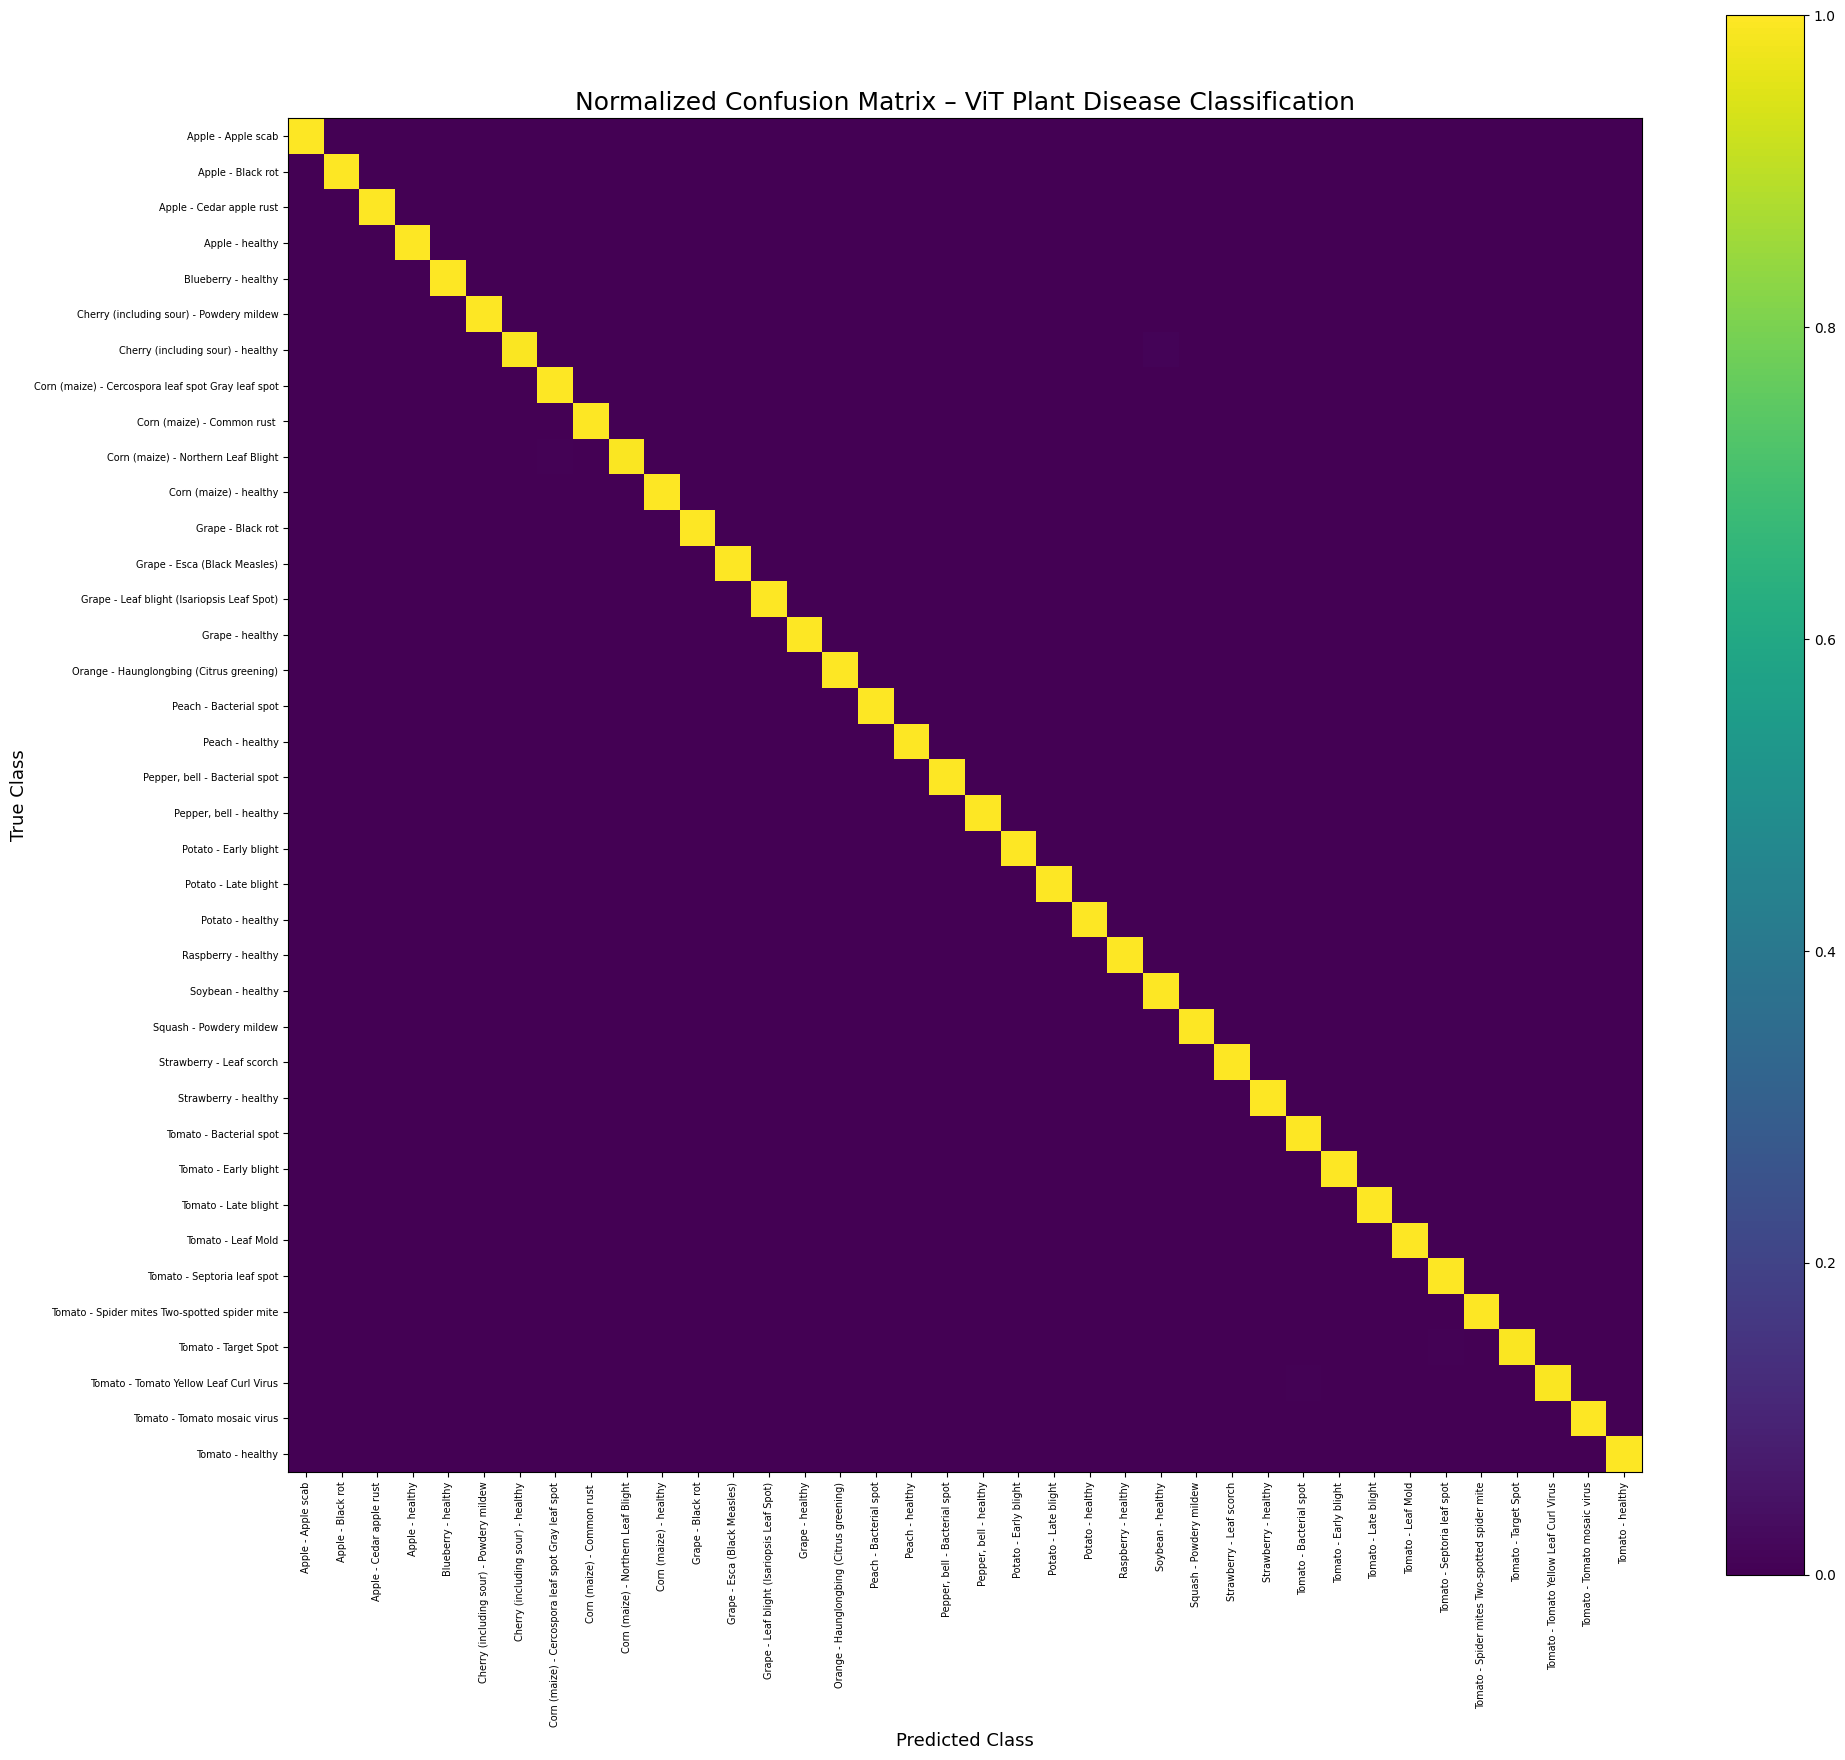

Saved to: /content/drive/MyDrive/Plant_Disease_ViT/confusion_matrix_normalized.png


In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# Create normalized confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(38)),
    normalize="true"
)

class_names = [id2label[i] for i in range(38)]

# Make labels easier to read
short_names = [
    name.replace("___", " - ").replace("_", " ")
    for name in class_names
]

plt.figure(figsize=(20, 18))

plt.imshow(cm, interpolation="nearest")
plt.title(
    "Normalized Confusion Matrix – ViT Plant Disease Classification",
    fontsize=18
)

plt.colorbar()

tick_marks = np.arange(len(short_names))

plt.xticks(
    tick_marks,
    short_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    tick_marks,
    short_names,
    fontsize=7
)

plt.xlabel("Predicted Class", fontsize=13)
plt.ylabel("True Class", fontsize=13)

plt.tight_layout()

SAVE_PATH = (
    "/content/drive/MyDrive/Plant_Disease_ViT/"
    "confusion_matrix_normalized.png"
)

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", SAVE_PATH)

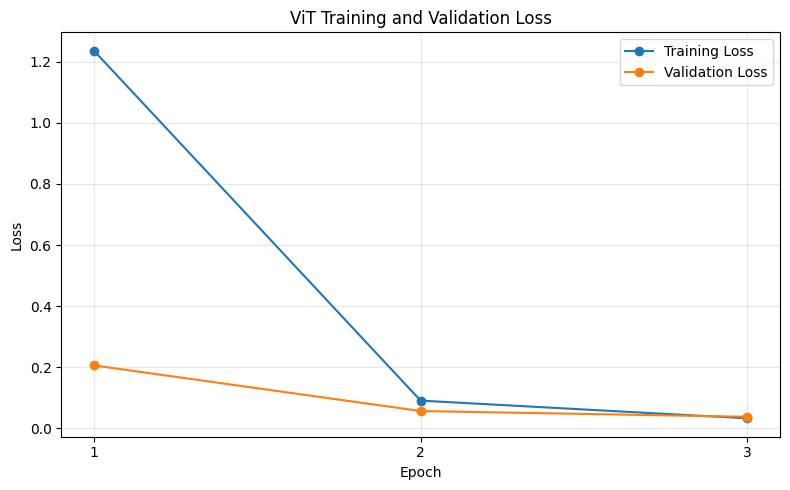

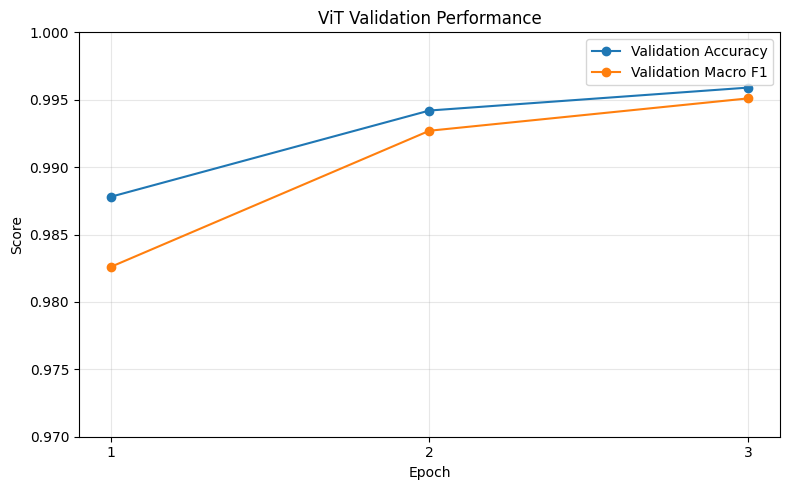

Saved:
/content/drive/MyDrive/Plant_Disease_ViT/training_validation_loss.png
/content/drive/MyDrive/Plant_Disease_ViT/validation_performance.png


In [8]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3]

train_loss = [1.2360, 0.0908, 0.0328]
val_loss = [0.2060, 0.0567, 0.0378]

val_accuracy = [0.9878, 0.9942, 0.9959]
val_f1 = [0.9826, 0.9927, 0.9951]

# ----- Loss Curve -----
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

loss_path = "/content/drive/MyDrive/Plant_Disease_ViT/training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

# ----- Validation Performance -----
plt.figure(figsize=(8, 5))
plt.plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")
plt.plot(epochs, val_f1, marker="o", label="Validation Macro F1")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("ViT Validation Performance")
plt.xticks(epochs)
plt.ylim(0.97, 1.0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

performance_path = "/content/drive/MyDrive/Plant_Disease_ViT/validation_performance.png"
plt.savefig(performance_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:")
print(loss_path)
print(performance_path)

In [ ]:
# Update model configuration with the real PlantVillage labels

model.config.label2id = label2id
model.config.id2label = id2label
model.config.num_labels = 38

print("Model label configuration updated!")

print("\nNumber of classes:", model.config.num_labels)

print("\nFirst 10 model labels:")
for i in range(10):
    print(f"{i} -> {model.config.id2label[i]}")

print("\nClassification head:")
print(model.classifier)

print("\nModel device:")
print(next(model.parameters()).device)

Model label configuration updated!

Number of classes: 38

First 10 model labels:
0 -> Apple___Apple_scab
1 -> Apple___Black_rot
2 -> Apple___Cedar_apple_rust
3 -> Apple___healthy
4 -> Blueberry___healthy
5 -> Cherry_(including_sour)___Powdery_mildew
6 -> Cherry_(including_sour)___healthy
7 -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 -> Corn_(maize)___Common_rust_
9 -> Corn_(maize)___Northern_Leaf_Blight

Classification head:
Linear(in_features=768, out_features=38, bias=True)

Model device:
cuda:0


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("\nBatch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one batch
batch = next(iter(train_loader))

print("\nBatch pixel_values shape:",
      batch["pixel_values"].shape)

print("Batch labels shape:",
      batch["labels"].shape)

DataLoaders created successfully!

Batch size: 16
Training batches: 2376
Validation batches: 510
Test batches: 510

Batch pixel_values shape: torch.Size([16, 3, 224, 224])
Batch labels shape: torch.Size([16])


In [ ]:
# Take one batch
batch = next(iter(train_loader))

pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

print("Images device:", pixel_values.device)
print("Labels device:", labels.device)

# Test one forward pass
model.train()

outputs = model(
    pixel_values=pixel_values,
    labels=labels
)

print("\nForward pass successful!")
print("Loss:", outputs.loss.item())
print("Logits shape:", outputs.logits.shape)

# Clear temporary GPU tensors
del outputs, pixel_values, labels
torch.cuda.empty_cache()

print("\nGPU test completed successfully!")

Images device: cuda:0
Labels device: cuda:0

Forward pass successful!
Loss: 3.6345911026000977
Logits shape: torch.Size([16, 38])

GPU test completed successfully!


In [ ]:
import torch
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score

# -----------------------------
# TRAINING CONFIGURATION
# -----------------------------

EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Total number of optimization steps
total_training_steps = len(train_loader) * EPOCHS

# 10% warm-up
warmup_steps = int(0.10 * total_training_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Training configuration ready!")

print("\nEpochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Training batches per epoch:", len(train_loader))
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Training configuration ready!

Epochs: 3
Learning rate: 2e-05
Weight decay: 0.01
Training batches per epoch: 2376
Total training steps: 7128
Warmup steps: 712


In [ ]:
import os
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Folder for best model
BEST_MODEL_PATH = "/content/best_plant_vit"

os.makedirs(BEST_MODEL_PATH, exist_ok=True)

# Mixed precision scaler for GPU
scaler = torch.amp.GradScaler("cuda")

# Store training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

best_val_f1 = -1.0

print("Starting ViT fine-tuning...\n")

for epoch in range(EPOCHS):

    # =====================================================
    # TRAINING
    # =====================================================

    model.train()

    running_train_loss = 0.0

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} - Training"
    )

    for batch in train_progress:

        pixel_values = batch["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision
        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(
                pixel_values=pixel_values,
                labels=labels
            )

            loss = outputs.loss

        scaler.scale(loss).backward()

        # Gradient clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        running_train_loss += loss.item()

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = (
        running_train_loss / len(train_loader)
    )


    # =====================================================
    # VALIDATION
    # =====================================================

    model.eval()

    running_val_loss = 0.0

    all_predictions = []
    all_labels = []

    val_progress = tqdm(
        val_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} - Validation"
    )

    with torch.no_grad():

        for batch in val_progress:

            pixel_values = batch["pixel_values"].to(
                device,
                non_blocking=True
            )

            labels = batch["labels"].to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(
                    pixel_values=pixel_values,
                    labels=labels
                )

            loss = outputs.loss

            running_val_loss += loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        running_val_loss / len(val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )


    # =====================================================
    # STORE HISTORY
    # =====================================================

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_f1"].append(val_f1)


    # =====================================================
    # EPOCH RESULTS
    # =====================================================

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Training Loss:   {avg_train_loss:.4f}"
    )

    print(
        f"Validation Loss: {avg_val_loss:.4f}"
    )

    print(
        f"Validation Accuracy: "
        f"{val_accuracy * 100:.2f}%"
    )

    print(
        f"Validation Macro F1: "
        f"{val_f1:.4f}"
    )


    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        model.save_pretrained(
            BEST_MODEL_PATH
        )

        image_processor.save_pretrained(
            BEST_MODEL_PATH
        )

        print(
            "✓ New best model saved!"
        )

    print("-" * 60)


print("\nTraining completed!")

print(
    f"Best Validation Macro F1: "
    f"{best_val_f1:.4f}"
)

print(
    f"Best model saved to: "
    f"{BEST_MODEL_PATH}"
)

Starting ViT fine-tuning...



Epoch 1/3 - Training:   0%|          | 0/2376 [00:00<?, ?it/s]

Epoch 1/3 - Validation:   0%|          | 0/510 [00:00<?, ?it/s]


Epoch 1/3
Training Loss:   1.2360
Validation Loss: 0.2060
Validation Accuracy: 98.78%
Validation Macro F1: 0.9826


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Epoch 3/3 - Training:   0%|          | 0/2376 [00:00<?, ?it/s]

Epoch 3/3 - Validation:   0%|          | 0/510 [00:00<?, ?it/s]


Epoch 3/3
Training Loss:   0.0328
Validation Loss: 0.0378
Validation Accuracy: 99.59%
Validation Macro F1: 0.9951


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ New best model saved!
------------------------------------------------------------

Training completed!
Best Validation Macro F1: 0.9951
Best model saved to: /content/best_plant_vit


In [15]:
from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Current temporary Colab model
SOURCE_MODEL = "/content/best_plant_vit"

# Permanent location in Google Drive
DRIVE_MODEL = "/content/drive/MyDrive/Plant_Disease_ViT/best_plant_vit"

# Create project directory
os.makedirs(
    "/content/drive/MyDrive/Plant_Disease_ViT",
    exist_ok=True
)

# Copy trained model
if os.path.exists(DRIVE_MODEL):
    shutil.rmtree(DRIVE_MODEL)

shutil.copytree(
    SOURCE_MODEL,
    DRIVE_MODEL
)

print("Best ViT model saved permanently!")

print("\nGoogle Drive location:")
print(DRIVE_MODEL)

print("\nSaved files:")
for filename in os.listdir(DRIVE_MODEL):
    print(" -", filename)

Mounted at /content/drive
Best ViT model saved permanently!

Google Drive location:
/content/drive/MyDrive/Plant_Disease_ViT/best_plant_vit

Saved files:
 - model.safetensors
 - config.json
 - preprocessor_config.json


In [16]:
import numpy as np
import torch

from transformers import AutoModelForImageClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tqdm.auto import tqdm


# ============================================================
# LOAD BEST SAVED MODEL
# ============================================================

DRIVE_MODEL = "/content/drive/MyDrive/Plant_Disease_ViT/best_plant_vit"

best_model = AutoModelForImageClassification.from_pretrained(
    DRIVE_MODEL
)

best_model = best_model.to(device)
best_model.eval()

print("Best model loaded successfully!")
print("Model device:", next(best_model.parameters()).device)


# ============================================================
# TEST SET EVALUATION
# ============================================================

test_predictions = []
test_labels = []

test_progress = tqdm(
    test_loader,
    desc="Evaluating Test Set"
)

with torch.no_grad():

    for batch in test_progress:

        pixel_values = batch["pixel_values"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = best_model(
                pixel_values=pixel_values
            )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )


# ============================================================
# CALCULATE METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)


print("\n========== FINAL TEST RESULTS ==========")

print(
    f"Test Accuracy:        "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision:      "
    f"{test_precision:.4f}"
)

print(
    f"Macro Recall:         "
    f"{test_recall:.4f}"
)

print(
    f"Macro F1 Score:       "
    f"{test_f1:.4f}"
)

print("\nNumber of test images:", len(test_labels))

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Best model loaded successfully!
Model device: cuda:0


Evaluating Test Set:   0%|          | 0/510 [00:00<?, ?it/s]


========== FINAL TEST RESULTS ==========
Test Accuracy:        99.63%
Macro Precision:      0.9956
Macro Recall:         0.9946
Macro F1 Score:       0.9950

Number of test images: 8146


In [17]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate per-class classification report
report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(38)),
    target_names=[id2label[i] for i in range(38)],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Keep the main class rows
class_report_df = report_df.iloc[:38].copy()

# Sort by F1 score to identify weakest classes
class_report_sorted = class_report_df.sort_values(
    by="f1-score",
    ascending=True
)

print("===== LOWEST PERFORMING CLASSES =====")

display(
    class_report_sorted[
        ["precision", "recall", "f1-score", "support"]
    ].head(10)
)

print("\n===== HIGHEST PERFORMING CLASSES =====")

display(
    class_report_sorted[
        ["precision", "recall", "f1-score", "support"]
    ].tail(10)
)

===== LOWEST PERFORMING CLASSES =====


,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.985714,0.896104,0.938776,77.0
Corn_(maize)___Northern_Leaf_Blight,0.948052,0.993197,0.970100,147.0
Tomato___Early_blight,0.979730,0.966667,0.973154,150.0
Tomato___Target_Spot,0.995192,0.981043,0.988067,211.0
Tomato___Spider_mites Two-spotted_spider_mite,0.984314,0.996032,0.990138,252.0
Tomato___Tomato_mosaic_virus,0.982456,1.000000,0.991150,56.0
Tomato___Late_blight,0.989583,0.993031,0.991304,287.0
Cherry_(including_sour)___healthy,1.000000,0.984375,0.992126,128.0
Tomato___Bacterial_spot,0.987616,1.000000,0.993769,319.0
Tomato___Septoria_leaf_spot,0.996226,0.996226,0.996226,265.0



===== HIGHEST PERFORMING CLASSES =====


,precision,recall,f1-score,support
Apple___healthy,1.0,1.0,1.0,246.0
Apple___Cedar_apple_rust,1.0,1.0,1.0,41.0
Cherry_(including_sour)___Powdery_mildew,1.0,1.0,1.0,158.0
Apple___Black_rot,1.0,1.0,1.0,93.0
Tomato___Leaf_Mold,1.0,1.0,1.0,143.0
Squash___Powdery_mildew,1.0,1.0,1.0,275.0
Strawberry___Leaf_scorch,1.0,1.0,1.0,167.0
Strawberry___healthy,1.0,1.0,1.0,68.0
"Pepper,_bell___Bacterial_spot",1.0,1.0,1.0,150.0
Tomato___healthy,1.0,1.0,1.0,239.0
